In [2]:
import xarray as xr
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
file = r'/Users/jpnousu/Models/pyAPES_main/results/FiHy_2012_2017.nc'
ds = xr.open_dataset(file)

m_file = r'/Users/jpnousu/Downloads/EVALUATION DATA/OBS_HYYTIALA.csv'
meteo = pd.read_csv(m_file, sep=';', index_col=0, parse_dates=True)

In [4]:
meteo['HS_man_min'] = meteo[['HS_man_70', 'HS_man_60', 'HS_man_80', 'HS_man_50', 'HS_man_100', 'HS_man_130', 'HS_man_160']].min(axis=1)
meteo['HS_man_max'] = meteo[['HS_man_70', 'HS_man_60', 'HS_man_80', 'HS_man_50', 'HS_man_100', 'HS_man_130', 'HS_man_160']].max(axis=1)

/opt/miniconda3/envs/pyapes/lib/python3.14/site-packages/pandas/plotting/_matplotlib/core.py:997: UserWarning: This axis already has a converter set and is updating to a potentially incompatible converter
  return ax.plot(*args, **kwds)


Text(0.5, 1.0, 'FI-Hy')

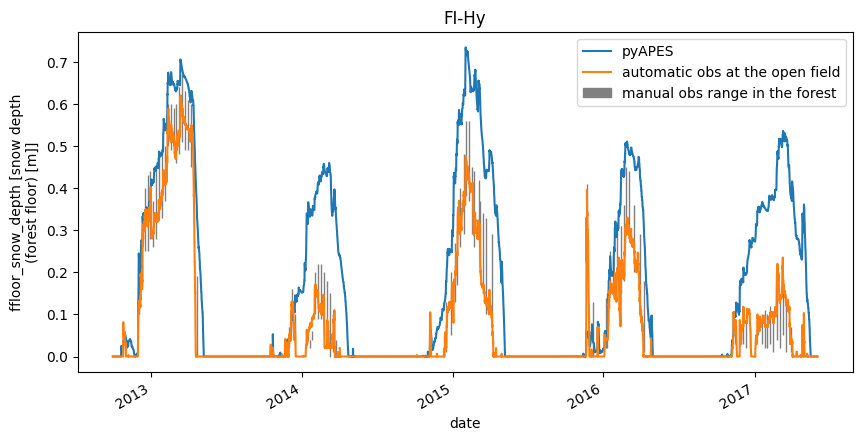

In [5]:
start = '2012-10-01'
end = '2017-06-01'

plt.figure(figsize=(10, 5))

ds['ffloor_snow_depth'].sel(date=slice(start, end)).plot(label='pyAPES')
meteo['HS_auto'].loc[start:end].plot(label='automatic obs at the open field')
#meteo['HS_man_max'].loc[start:end].plot(label='HS_man_min')
#plt.scatter(meteo.loc[start:end].index,
#                 meteo['HS_man_min'].loc[start:end],
#                 color='gray', alpha=1.0, s=5)
#plt.scatter(meteo.loc[start:end].index,
#                 meteo['HS_man_max'].loc[start:end],
#                 color='gray', alpha=1.0, s=5)
plt.fill_between(meteo.loc[start:end].index,
                 meteo['HS_man_min'].loc[start:end],
                 meteo['HS_man_max'].loc[start:end],
                 color='gray', alpha=1.0, label='manual obs range in the forest')

plt.legend()
plt.title('FI-Hy')

/opt/miniconda3/envs/pyapes/lib/python3.14/site-packages/pandas/plotting/_matplotlib/core.py:997: UserWarning: This axis already has a converter set and is updating to a potentially incompatible converter
  return ax.plot(*args, **kwds)


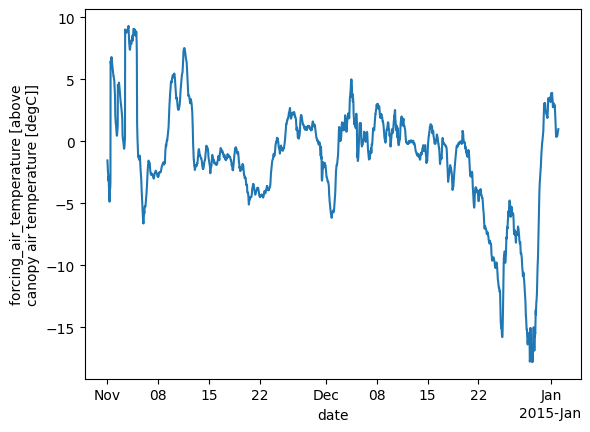

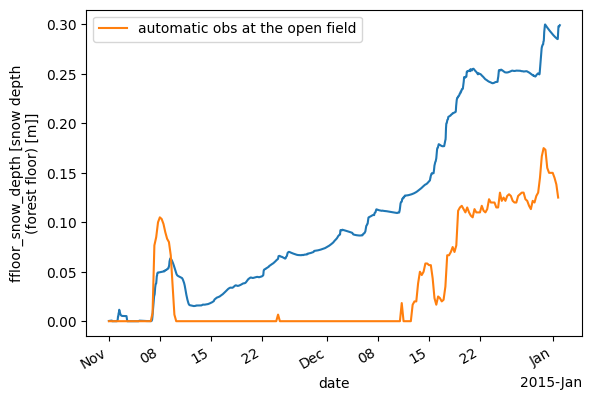

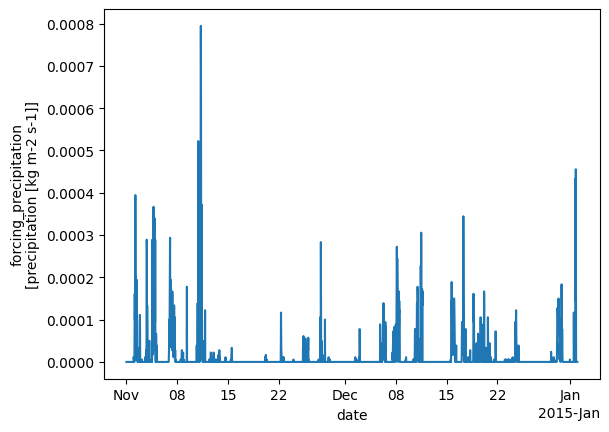

In [13]:
start = '2014-11-01'
end = '2015-01-01'
plt.figure(0)
ds['forcing_air_temperature'].sel(date=slice(start, end)).plot()
plt.figure(1)
ds['ffloor_snow_depth'].sel(date=slice(start, end)).plot()
meteo['HS_auto'].loc[start:end].plot(label='automatic obs at the open field')
plt.legend()
plt.figure(2)
ds['forcing_precipitation'].sel(date=slice(start, end)).plot()


